# Phân tích mini-pilot (lộ trình Tuần 8, mục 8.3)

Mục đích (8.3): tính metric, vẽ phân phối, xác nhận lại lựa chọn kiểm định; mục pilot **không** đưa vào phân tích xác nhận.
Đầu vào: `results/pilot_sessions/*/grade/summary.json` (kết quả `junit_eval.py`), `results/pilot_sessions.csv`, `data/lich_phien_minipilot.csv`.
Metric tính bằng `tools/gap1-pilot/compute_metric.py` (gate E4, có ca kiểm tra tính tay: `python compute_metric.py --self-test`).

Quy tắc phiên dùng ở đây: Before không biên dịch → WADR(Before) = 0 (proposal §5.3). After không biên dịch (đăng ký trước ngày 11/11/2026): phân tích chính **không tính** phiên đó, độ nhạy coi WADR(After) = 0.

In [1]:
import sys, json, csv, collections
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
ROOT = Path('..').resolve()
sys.path.insert(0, str(ROOT / 'tools' / 'gap1-pilot'))
import compute_metric as cm
SESS, SAMPLE = ROOT / 'results' / 'pilot_sessions', ROOT / 'data' / 'lich_phien_minipilot.csv'
FIG = ROOT / 'results' / 'figures'; FIG.mkdir(exist_ok=True)
COL = {'J': '#2a78d6', 'P': '#eb6834'}   # slot 1, 2 của bảng màu phân loại đã kiểm định
plt.rcParams.update({'font.size': 10, 'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.edgecolor': '#52514e', 'axes.labelcolor': '#0b0b0b', 'xtick.color': '#52514e',
                     'ytick.color': '#52514e', 'axes.grid': True, 'grid.color': '#e6e5e1', 'grid.linewidth': 0.6,
                     'figure.facecolor': '#fcfcfb', 'axes.facecolor': '#fcfcfb'})
pd.set_option('display.width', 160)

## 1. Kiểm tra pipeline (tiêu chí 8.4)

In [2]:
sess_tbl = pd.read_csv(ROOT / 'results' / 'pilot_sessions.csv')
print('Số phiên có dữ liệu:', len(sess_tbl), '/ 10')
print('Before biên dịch được:', (sess_tbl['bien_dich_before'] == 'ok').sum(), '/', len(sess_tbl))
print('\nThời gian một lần chạy công cụ (giây, trung bình theo phiên):')
print(sess_tbl.groupby('dieu_kien')['tool_giay_tb'].describe()[['count', 'mean', 'min', 'max']].round(1).to_string())
print('\nThời gian chấm một phiên (giây):', sess_tbl['cham_giay'].describe()[['mean', 'min', 'max']].round(1).to_dict())

Số phiên có dữ liệu: 10 / 10
Before biên dịch được: 10 / 10

Thời gian một lần chạy công cụ (giây, trung bình theo phiên):
           count  mean  min  max
dieu_kien                       
J            5.0   5.0  3.2  6.8
P            5.0   7.0  5.4  7.9

Thời gian chấm một phiên (giây): {'mean': 270.6, 'min': 70.8, 'max': 600.1}


## 2. Metric theo phiên ở các mốc T = 15, 20, 30 phút

In [3]:
rows = []
for T in ['after_T15', 'after_T20', 'after_T30']:
    for s in cm.load_sessions(SESS, SAMPLE, T, 'bo'):
        rows.append({**s, 'T': int(T[-2:])})
df = pd.DataFrame(rows)
wide = df[df['T'] == 20].set_index('session_id')[['sv_id', 'trinh_do', 'pid', 'dieu_kien', 'WADR_before']].rename(columns={'WADR_before': 'Before'})
for t in (15, 20, 30):
    wide[f'After T{t}'] = df[df['T'] == t].set_index('session_id')['WADR_after']
print(wide.round(4).to_string())
print('\nGhi chú:', {r.session_id: r.ghi_chu for r in df[df['T'] == 20].itertuples() if r.ghi_chu})

           sv_id     trinh_do     pid dieu_kien  Before  After T15  After T20  After T30
session_id                                                                              
S01          SV1  semi-senior  p03986         J  0.2353     0.2706     0.2706     0.3529
S02          SV1  semi-senior  p02909         P  1.0000     1.0000     1.0000     1.0000
S03          SV2       junior  p03986         P  0.2353     0.2471     0.2471     0.2471
S04          SV2       junior  p02909         J  1.0000     1.0000     1.0000     1.0000
S05          SV3       junior  p02909         J  1.0000     1.0000     1.0000     1.0000
S06          SV3       junior  p03986         P  0.2353     0.2353     0.2353     0.2353
S07          SV4      fresher  p02909         P  1.0000     1.0000     1.0000     1.0000
S08          SV4      fresher  p03986         J  0.0000        NaN        NaN        NaN
S09          SV5       junior  p03986         J  0.2353     0.1294     0.0000     0.0000
S10          SV5     

## 3. Hiện tượng chạm trần

Chỉ số đã nêu trong email 23/10 (phương án b): tỉ lệ phiên có WADR(After) ≥ 0,95. Thêm tỉ lệ phiên **đã** ≥ 0,95 ngay ở Before (trần không phụ thuộc phản hồi).

In [4]:
t20 = df[df['T'] == 20]
for pid, g in t20.groupby('pid'):
    b = (g['WADR_before'] >= 0.95).mean(); a = (g['WADR_after'].dropna() >= 0.95).mean()
    print(f'{pid}: Before ≥ 0,95: {b:.0%} ({(g.WADR_before>=0.95).sum()}/{len(g)}); After(T20) ≥ 0,95: {a:.0%} '
          f'({(g.WADR_after>=0.95).sum()}/{g.WADR_after.notna().sum()})')

p02909: Before ≥ 0,95: 80% (4/5); After(T20) ≥ 0,95: 80% (4/5)
p03986: Before ≥ 0,95: 0% (0/5); After(T20) ≥ 0,95: 0% (0/4)


## 4. Phân phối

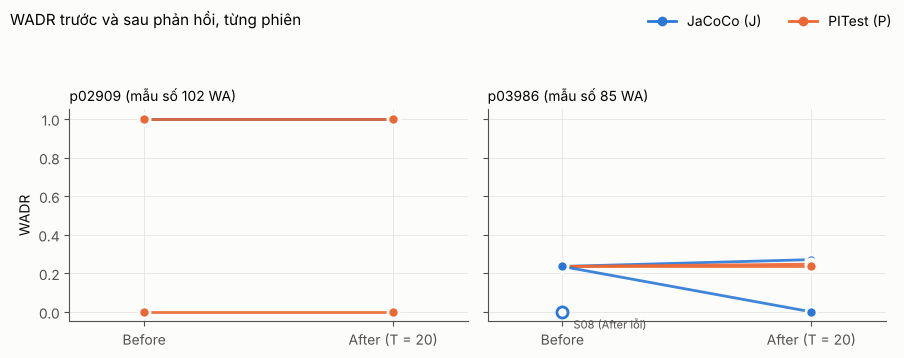

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.6), sharey=True)
for ax, (pid, g) in zip(axes, t20.groupby('pid')):
    for r in g.itertuples():
        if r.WADR_after is None or pd.isna(r.WADR_after):
            ax.plot([0], [r.WADR_before], 'o', ms=8, mfc='white', mec=COL[r.dieu_kien], mew=2)
            ax.annotate(f'{r.session_id} (After lỗi)', (0, r.WADR_before), xytext=(8, -12), textcoords='offset points',
                        fontsize=8, color='#52514e')
            continue
        ax.plot([0, 1], [r.WADR_before, r.WADR_after], '-', color=COL[r.dieu_kien], lw=2, alpha=0.9)
        ax.plot([0, 1], [r.WADR_before, r.WADR_after], 'o', ms=8, color=COL[r.dieu_kien], mec='#fcfcfb', mew=2)
    ax.set_xticks([0, 1], ['Before', 'After (T = 20)']); ax.set_xlim(-0.3, 1.3); ax.set_ylim(-0.05, 1.05)
    ax.set_title(f'{pid} (mẫu số {int(g.WA_mau_so.dropna().iloc[0])} WA)', fontsize=10, loc='left')
axes[0].set_ylabel('WADR')
h = [plt.Line2D([], [], color=COL[k], lw=2, marker='o', label=l) for k, l in [('J', 'JaCoCo (J)'), ('P', 'PITest (P)')]]
fig.legend(handles=h, loc='upper right', ncol=2, frameon=False)
fig.suptitle('WADR trước và sau phản hồi, từng phiên', x=0.01, ha='left', fontsize=11)
fig.tight_layout(rect=(0, 0, 1, 0.9)); fig.savefig(FIG / 'pilot_wadr_before_after.png', dpi=150); plt.show()

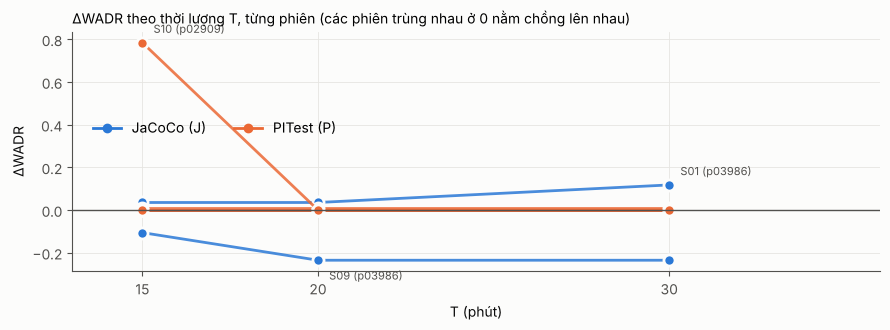

Số phiên có ΔWADR ≠ 0 ở T15 / T20 / T30: [4, 3, 3] trên 9


In [6]:
fig, ax = plt.subplots(figsize=(9, 3.4))
dd = df.dropna(subset=['dWADR'])
for k, (sid, g) in enumerate(dd.groupby('session_id')):
    g = g.sort_values('T'); c = COL[g.dieu_kien.iloc[0]]
    ax.plot(g['T'], g['dWADR'], '-', color=c, lw=2, alpha=0.85)
    ax.plot(g['T'], g['dWADR'], 'o', color=c, ms=8, mec='#fcfcfb', mew=2)
    if (g.dWADR.abs() > 0.02).any():
        pk = g.loc[g.dWADR.abs().idxmax()]
        ax.annotate(f'{sid} ({pk.pid})', (pk['T'], pk.dWADR), xytext=(8, 10 if pk.dWADR > 0 else -11), textcoords='offset points',
                    fontsize=8, va='center', color='#52514e')
ax.axhline(0, color='#52514e', lw=1)
ax.set_xticks([15, 20, 30]); ax.set_xlabel('T (phút)'); ax.set_ylabel('ΔWADR'); ax.set_xlim(13, 36)
ax.legend(handles=h, loc='center left', bbox_to_anchor=(0.01, 0.6), frameon=False, ncol=2)
ax.set_title('ΔWADR theo thời lượng T, từng phiên (các phiên trùng nhau ở 0 nằm chồng lên nhau)', fontsize=10, loc='left')
fig.tight_layout(); fig.savefig(FIG / 'pilot_dwadr_theo_T.png', dpi=150); plt.show()
print('Số phiên có ΔWADR ≠ 0 ở T15 / T20 / T30:',
      [int((dd[dd['T'] == t]['dWADR'].abs() > 1e-12).sum()) for t in (15, 20, 30)], 'trên', dd[dd['T']==20].shape[0])

## 5. Xác nhận lựa chọn kiểm định (§6)

Kiểm định đã chốt: Wilcoxon signed-rank hai phía trên d = ΔWADR(P) − ΔWADR(J), hiệu bằng 0 theo Pratt, ước lượng Hodges–Lehmann.
Câu hỏi 8.3: dữ liệu pilot có cho thấy đặc điểm khiến lựa chọn này không phù hợp không? Kiểm tra: dữ liệu ghép cặp; tỉ lệ hiệu bằng 0 và hạng trùng (lý do chọn Pratt); hình dạng phân phối (lý do không dùng t ghép cặp).

In [7]:
res = cm.analyse(cm.load_sessions(SESS, SAMPLE, 'after_T20', 'bo'))
pv = pd.DataFrame(res['theo_sinh_vien'])
print(pv.round(4).to_string(index=False))
d = np.array(res['d'])
print(f"\nn ghép cặp = {res['n_ghep_cap']}; số d = 0: {(d == 0).sum()}; số |d| trùng nhau: {len(d[d!=0]) - len(np.unique(np.abs(d[d!=0])))}")
print(f"θ̂ (Hodges–Lehmann) = {res['HL_theta']:.4f}; Wilcoxon (Pratt) p = {res['p']:.4f}; kết luận theo quy tắc: {res['ket_luan']}")
print('(Chỉ để kiểm tra script chạy được; mục pilot không dùng để kết luận RQ.)')

sv_id  dWADR_J  dWADR_P       d  trong_phan_tich
  SV1   0.0353   0.0000 -0.0353             True
  SV2   0.0000   0.0118  0.0118             True
  SV3   0.0000   0.0000  0.0000             True
  SV4      NaN   0.0000     NaN            False
  SV5  -0.2353   0.0000  0.2353             True

n ghép cặp = 4; số d = 0: 1; số |d| trùng nhau: 0
θ̂ (Hodges–Lehmann) = 0.0088; Wilcoxon (Pratt) p = 0.5775; kết luận theo quy tắc: chưa thấy khác biệt
(Chỉ để kiểm tra script chạy được; mục pilot không dùng để kết luận RQ.)


In [8]:
print('Độ nhạy:')
for T in ['after_T15', 'after_T20', 'after_T30']:
    for pol in ['bo', 'bang_0']:
        r = cm.analyse(cm.load_sessions(SESS, SAMPLE, T, pol))
        print(f"  {T}, After lỗi = {pol:6s}: n = {r['n_ghep_cap']}, θ̂ = {r['HL_theta']:+.4f}, p = {r['p']:.4f}, {r['ket_luan']}")

Độ nhạy:
  after_T15, After lỗi = bo    : n = 4, θ̂ = +0.0088, p = 0.5775, chưa thấy khác biệt
  after_T15, After lỗi = bang_0: n = 5, θ̂ = +0.0059, p = 0.5716, chưa thấy khác biệt
  after_T20, After lỗi = bo    : n = 4, θ̂ = +0.0088, p = 0.5775, chưa thấy khác biệt
  after_T20, After lỗi = bang_0: n = 5, θ̂ = +0.0059, p = 0.5716, chưa thấy khác biệt
  after_T30, After lỗi = bo    : n = 4, θ̂ = +0.0088, p = 0.5775, chưa thấy khác biệt
  after_T30, After lỗi = bang_0: n = 5, θ̂ = +0.0059, p = 0.5716, chưa thấy khác biệt


In [9]:
print('Độ lệch chuẩn của ΔWADR (T20) theo bài, chỉ để tham khảo cho bảng power_sim (σ):')
print(t20.dropna(subset=['dWADR']).groupby('pid')['dWADR'].agg(['count', 'mean', 'std']).round(4).to_string())

Độ lệch chuẩn của ΔWADR (T20) theo bài, chỉ để tham khảo cho bảng power_sim (σ):
        count    mean     std
pid                          
p02909      5  0.0000  0.0000
p03986      4 -0.0471  0.1263


## 6. Kết luận cho quyết định 8.4

Ô dưới in tóm tắt tự động từ các số ở trên; diễn giải đầy đủ ở `BAO_CAO_MINIPILOT_1_SINH_VIEN.md`.

In [10]:
print(f"1. Pipeline: {len(sess_tbl)}/10 phiên chạy hết (Before, 4 lần chạy công cụ, chấm).")
print(f"2. Metric tính được ở {int(t20.dWADR.notna().sum())}/{len(t20)} phiên (T20).")
print(f"3. Trần: p02909 có {(t20[t20.pid=='p02909'].WADR_before >= 0.95).sum()}/5 phiên ≥ 0,95 ngay ở Before.")
print(f"4. ΔWADR khác 0 ở {int((t20.dWADR.abs() > 1e-12).sum())}/{int(t20.dWADR.notna().sum())} phiên (T20) -> phân phối khác dự kiến; giảng viên quyết (8.4).")
print("5. Kiểm định: dữ liệu ghép cặp; nhiều phiên có ΔWADR = 0 nên d dễ bằng 0 hoặc trùng hạng; phân phối lệch (SV5) -> Wilcoxon theo Pratt và ước lượng Hodges–Lehmann vẫn là lựa chọn phù hợp; giữ nguyên như proposal.")

1. Pipeline: 10/10 phiên chạy hết (Before, 4 lần chạy công cụ, chấm).
2. Metric tính được ở 9/10 phiên (T20).
3. Trần: p02909 có 4/5 phiên ≥ 0,95 ngay ở Before.
4. ΔWADR khác 0 ở 3/9 phiên (T20) -> phân phối khác dự kiến; giảng viên quyết (8.4).
5. Kiểm định: dữ liệu ghép cặp; nhiều phiên có ΔWADR = 0 nên d dễ bằng 0 hoặc trùng hạng; phân phối lệch (SV5) -> Wilcoxon theo Pratt và ước lượng Hodges–Lehmann vẫn là lựa chọn phù hợp; giữ nguyên như proposal.
